In [ ]:
using JLD2
using LinearAlgebra
using CairoMakie

#To get the exact Eigen Space for Comparison
function TrueEigenSpace(Operator::Tuple{Vector,Vector,Vector},num_Qbits::Int,dim::Int) 
    N,d=num_Qbits,dim
    a,b,c=Operator
    M=zeros((d^N,d^N))
    for j in 1:d^N -1
        M[j,j]=a[j]
        M[j,j+1]=b[j]
        M[j+1,j]=c[j]
    end
    M[d^N,d^N]=a[d^N]
    E=eigen(M)
    permutation=sortperm(abs.(E.values))
    psi=E.vectors[:,permutation]
    lambda=E.values[permutation]
    return lambda,psi'
end

function TrueEigenSpace(Operator::Tuple{Number,Number,Number},num_Qbits::Int,dim::Int) 
    N,d=num_Qbits,dim
    a,b,c=Operator   
    M=zeros((d^N,d^N))
    for j in 1:d^N -1
        M[j,j]=a
        M[j,j+1]=b
        M[j+1,j]=c
    end
    M[d^N,d^N]=a
    E=eigen(M)
    permutation=sortperm(abs.(E.values))
    psi=E.vectors[:,permutation]
    lambda=E.values[permutation]
    return lambda,psi'
end
# Parameters
Num=10

Nx,Ny=(2^Num),(2^Num)  # grid points in x and y
xmax,ymax=1.0,1.0

mωx2,mωy2=1.0,10.0
λx,λy=1.0,5.0  # anharmonic (quartic) coefficients

Nmodes=50
dt = 0.1
N1 = 5000
N2 = 10000
N3 = 20000

x=LinRange(-xmax,xmax,Nx)
y=LinRange(-ymax,ymax,Ny)

dx=x[2] - x[1]
dy=y[2] - y[1]


function AnHOX(Num)
    Nx=2^Num

    x=LinRange(-xmax,xmax,Nx)
    dx=x[2] - x[1]

    ax=(-2*3.81) .- ((0.5*mωx2 * x.^2 .+ λx * x.^4) .* dx^2)

    bx=ones(Nx-1)
    return (ax,bx,bx)
end

function AnHOY(Num)
    Ny=2^Num

    y=LinRange(-ymax,ymax,Ny)
    dy=y[2] - y[1]

    ay=(-2*3.81) .- ((0.5*mωy2 * y.^2 .+ λy * y.^4) .* dy^2)

    by=ones(Ny-1)
    return (ay,by,by)
end

Num        = 10
Nmodes     = 50
steps_list = [20000, 10000, 5000]


fileXvec(steps) = "AnhoXvec_$(Num)Qubit_dt0.1_Steps$(steps).jld2"
fileXval(steps) = "AnhoXval_$(Num)Qubit_dt0.1_Steps$(steps).jld2"

fileYvec(steps) = "AnhoYvec_$(Num)Qubit_dt0.1_Steps$(steps).jld2"
fileYval(steps) = "AnhoYval_$(Num)Qubit_dt0.1_Steps$(steps).jld2"


λ_refX, Ψ_refX = TrueEigenSpace(AnHOX(Num), Num, 2)
λ_refY, Ψ_refY = TrueEigenSpace(AnHOY(Num), Num, 2)

λ_refX = λ_refX[1:Nmodes]
λ_refY = λ_refY[1:Nmodes]

Ψ_refX = Ψ_refX[1:Nmodes, :]
Ψ_refY = Ψ_refY[1:Nmodes, :]

states = 1:Nmodes


eigval_err_X = Dict{Int, Vector{Float64}}()
eigval_err_Y = Dict{Int, Vector{Float64}}()
fid_X        = Dict{Int, Vector{Float64}}()
fid_Y        = Dict{Int, Vector{Float64}}()

for steps in steps_list

    # ---- Load X ----
    @load fileXvec(steps) Ψ_x
    @load fileXval(steps) l_x

    λX = l_x[1:Nmodes]
    ΨX = Ψ_x[1:Nmodes]

    rel_err_X = abs.(λX .- λ_refX) ./ abs.(λ_refX)

    fidelity_X = zeros(Nmodes)
    for n in 1:Nmodes
        overlap = dot(conj.(Ψ_refX[n, :]), ΨX[n])
        fidelity_X[n] = abs(overlap)^2
    end

    eigval_err_X[steps] = rel_err_X
    fid_X[steps]        = fidelity_X

    # ---- Load Y ----
    @load fileYvec(steps) Ψ_y
    @load fileYval(steps) l_y

    λY = l_y[1:Nmodes]
    ΨY = Ψ_y[1:Nmodes]

    rel_err_Y = abs.(λY .- λ_refY) ./ abs.(λ_refY)

    fidelity_Y = zeros(Nmodes)
    for n in 1:Nmodes
        overlap = dot(conj.(Ψ_refY[n, :]), ΨY[n])
        fidelity_Y[n] = abs(overlap)^2
    end

    eigval_err_Y[steps] = rel_err_Y
    fid_Y[steps]        = fidelity_Y
end



┌ Warning: Found `resolution` in the theme when creating a `Scene`. The `resolution` keyword for `Scene`s and `Figure`s has been deprecated. Use `Figure(; size = ...` or `Scene(; size = ...)` instead, which better reflects that this is a unitless size and not a pixel resolution. The key could also come from `set_theme!` calls or related theming functions.
└ @ Makie C:\Users\vishw\.julia\packages\Makie\4JW9B\src\scenes.jl:264


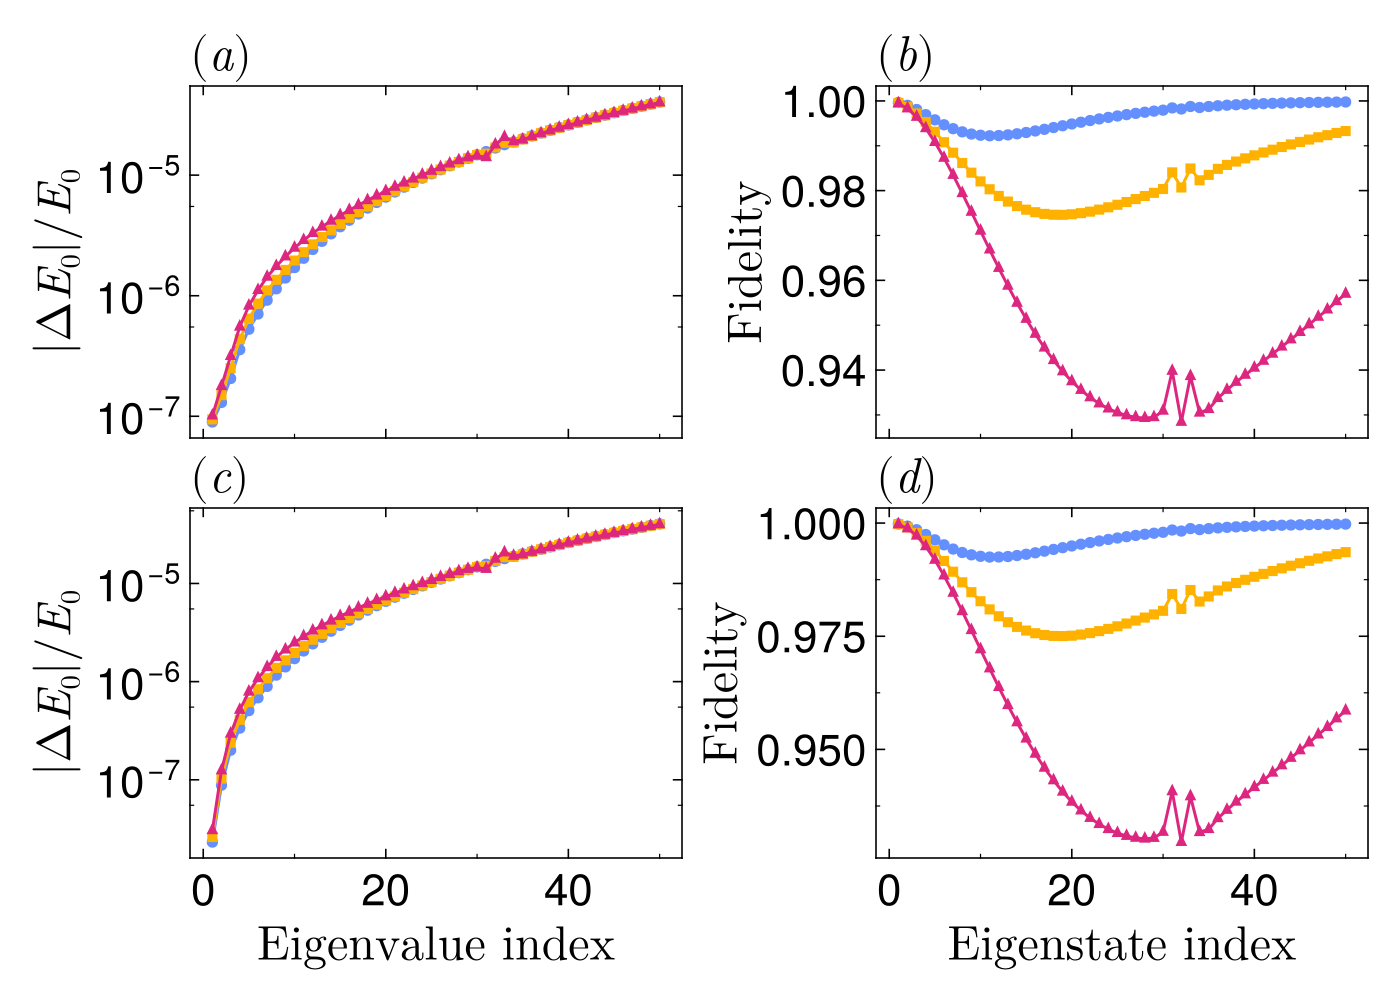

In [ ]:
# --------------------------------------------------
# FIGURE (PRL Style - Two Column)
# --------------------------------------------------

using CairoMakie

CairoMakie.set_theme!(Theme(
    fontsize = 11,
    font = "Times New Roman",
    Axis = (
        xgridvisible = false,
        ygridvisible = false,
        xlabelsize = 24,
        ylabelsize = 24,
        titlesize = 24,
        xticklabelsize = 22,
        yticklabelsize = 22,
        spinewidth = 0.8,
        xtickwidth = 0.8,
        ytickwidth = 0.8,
        xticksize = 5,
        yticksize = 5,
        xminorticksize = 2.5,
        yminorticksize = 2.5,
        xminorticksvisible = true,
        yminorticksvisible = true,
        xminortickwidth = 0.6,
        yminortickwidth = 0.6,
        ticklabelfont = "Times New Roman",
        labelfont = "Times New Roman",
        titlefont = "Times New Roman",
		xtickalign = 1,
		ytickalign = 1,
		xminortickalign = 1,
		yminortickalign = 1,
		xticksmirrored = true,
		yticksmirrored = true,

    ),
))

fig = CairoMakie.Figure(resolution = (700, 500), backgroundcolor = :white)

ax1 = CairoMakie.Axis(fig[1,1],
    xlabel = L"Eigenvalue index$$",
    ylabel = L"$\left|\Delta E_0\right|/E_0$",
    yscale = CairoMakie.log10,
    title = L"(a)",
    titlealign = :left,
    titlegap = 2,
)

ax2 = CairoMakie.Axis(fig[1,2],
    xlabel = L"Eigenstate index$$",
    ylabel = L"Fidelity$$",
    title = L"(b)",
    titlealign = :left,
    titlegap = 2,
)

ax3 = CairoMakie.Axis(fig[2,1],
    xlabel = L"Eigenvalue index$$",
    ylabel = L"$\left|\Delta E_0\right|/E_0$",
    yscale = CairoMakie.log10,
    title = L"(c)",
    titlealign = :left,
    titlegap = 2,
)

ax4 = CairoMakie.Axis(fig[2,2],
    xlabel = L"Eigenstate index$$",
    ylabel = L"Fidelity$$",
    title = L"(d)",
    titlealign = :left,
    titlegap = 2,
)

palette = [
    RGBf(0.392, 0.561, 1.0),    # ultramarine
    RGBf(1.0, 0.694, 0.0),      # gold
    RGBf(0.867, 0.149, 0.498),  # magenta
]

markers = [:circle, :rect, :utriangle]
msize   = 8

for (i, steps) in enumerate(steps_list)
    col = palette[i]
    mk  = markers[i]

    for (ax, data) in [
        (ax1, eigval_err_X[steps]),
        (ax2, fid_X[steps]),
        (ax3, eigval_err_Y[steps]),
        (ax4, fid_Y[steps]),
    ]
        CairoMakie.lines!(ax, states, data;
            color     = col,
            linewidth = 1.5,
            linestyle = :solid,
			alpha = 1.0)

        CairoMakie.scatter!(ax, states, data;
            color       = col,
            marker      = mk,
            markersize  = msize,
            #strokewidth = 0
			#color = :transparent,
            strokecolor = col,
            strokewidth = 0.0)
    end
end

# Link only x axes
CairoMakie.linkxaxes!(ax1, ax2, ax3, ax4)

# Hide x tick labels on top row only
CairoMakie.hidexdecorations!(ax1, ticks = false, minorticks = false)
CairoMakie.hidexdecorations!(ax2, ticks = false, minorticks = false)

CairoMakie.colgap!(fig.layout, 8)
CairoMakie.rowgap!(fig.layout, 8)

save("2D_Anharmonic_Oscillator_PRL.pdf", fig)

fig